# Representaciones Lineales de Perspectiva Política en LLMs (Chile)
notebook que presenta los resultados obtenidos al replicar la metodología de "Linear Representations of Political Perspective Emerge in Large Language Models" (ICLR 2025) aplicada al contexto político chileno (Diputados 2022-2026).

## 1. Configuración y Carga de Datos

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr

# Rutas
BASE_DIR = Path("..")
RESULTS_DIR = BASE_DIR / "results_replication/v2"
DATA_DIR = BASE_DIR / "data"
MODELS = [
        'meta-llama/Meta-Llama-3-8B-Instruct', 
        'mistralai/Mistral-7B-Instruct-v0.3', 
        'Qwen/Qwen2.5-7B-Instruct'
]

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['font.size'] = 12

# Cargar metadata de parlamentarios para enriquecer gráficos
df_meta = pd.read_parquet(DATA_DIR / "congreso_2022_2026_20intervenciones.parquet")

## 2. Heatmaps de Capacidad Predictiva (Spearman Correlation)
Cada celda representa la correlación de Spearman entre las predicciones de un probe lineal entrenado en una cabeza de atención específica y los puntajes DW_NOMINATE de los parlamentarios.

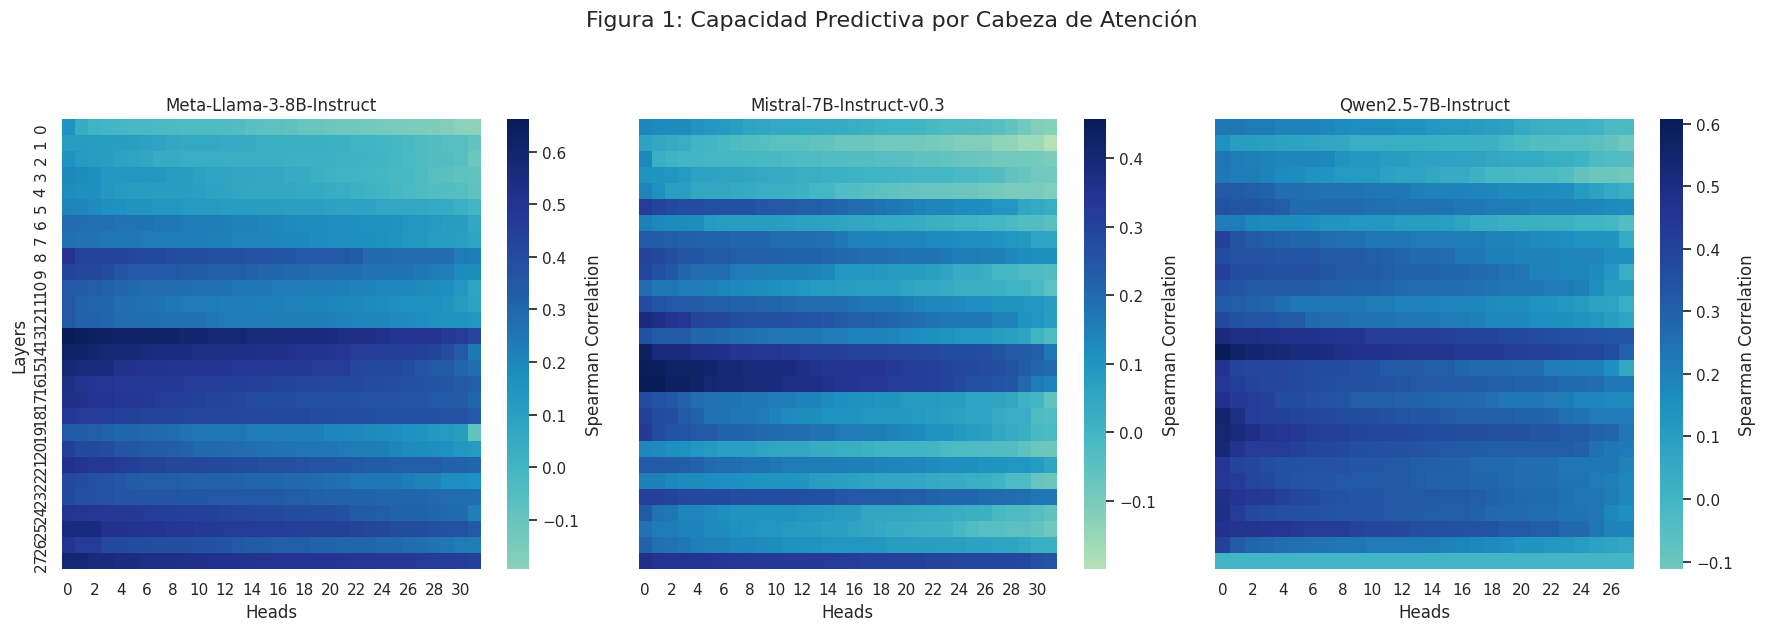

In [18]:
def plot_model_heatmaps(models):
    fig, axes = plt.subplots(1, len(models), figsize=(18, 6), sharey=True)
    
    for i, model_name in enumerate(models):
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists():
            print(f"Faltan datos para {model_name}")
            continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
        
        # Ordenar cabezas (mas predictivas a la izquierda)
        performance = np.sort(np.array(performance), axis=1)[:, ::-1]
            
        sns.heatmap(performance, ax=axes[i], cmap='YlGnBu', center=0, cbar_kws={'label': 'Spearman Correlation'})
        axes[i].set_title(model_name.split('/')[-1])
        axes[i].set_xlabel('Heads')
        if i == 0:
            axes[i].set_ylabel('Layers')
            
    plt.suptitle("Figura 1: Capacidad Predictiva por Cabeza de Atención", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

plot_model_heatmaps(MODELS)

## 3. Rendimiento por Capa
Visualización del rendimiento máximo y promedio por capa para identificar dónde se concentra la información política.

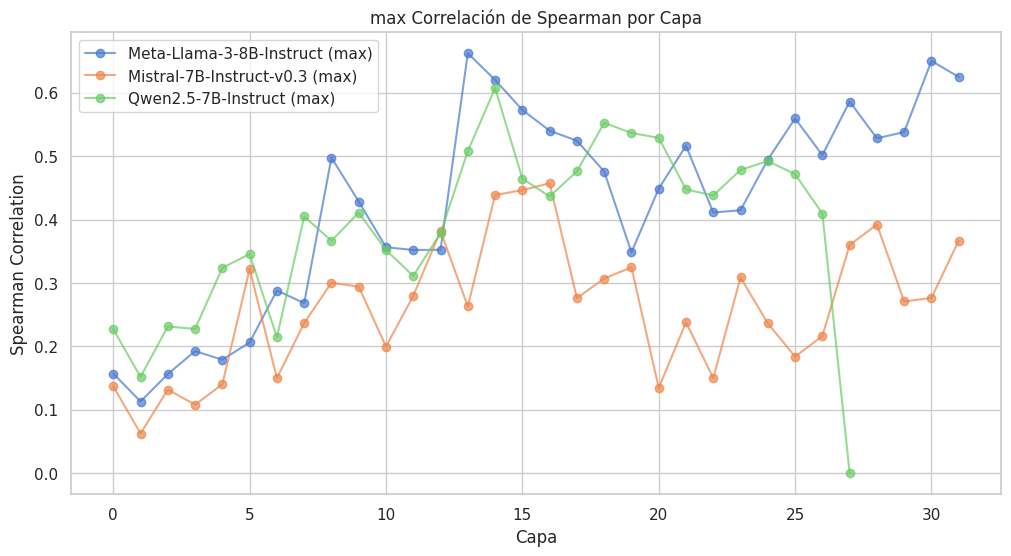

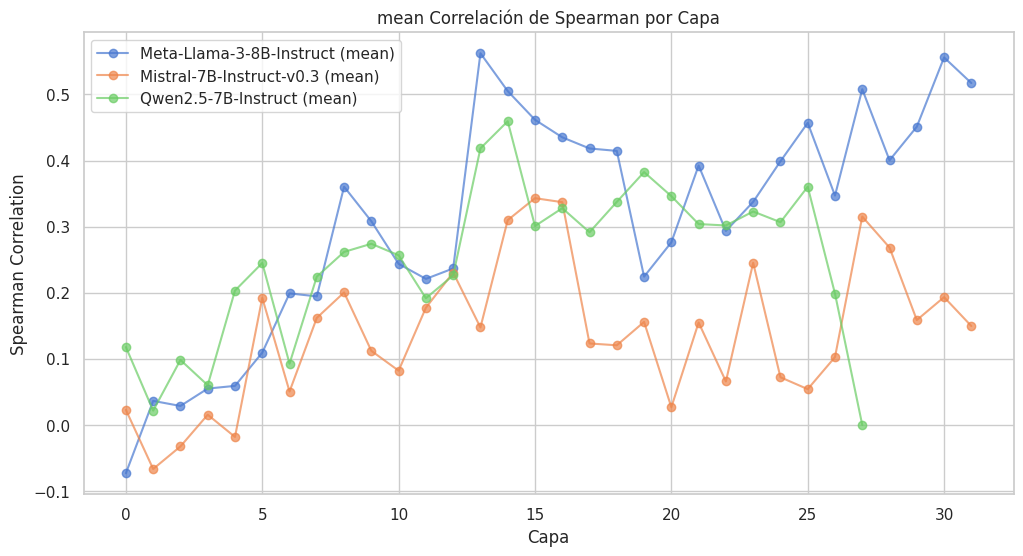

In [5]:
def plot_layer_performance(models, fn):
    plt.figure(figsize=(12, 6))
    
    for model_name in models:
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists(): continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        max_perf = fn(performance, axis=1)
        plt.plot(max_perf, label=f"{model_name.split('/')[-1]} ({fn.__name__})", marker='o', alpha=0.7)
        
    plt.title(f"{fn.__name__} Correlación de Spearman por Capa")
    plt.xlabel("Capa")
    plt.ylabel("Spearman Correlation")
    plt.legend()
    plt.show()

plot_layer_performance(MODELS, np.max)
plot_layer_performance(MODELS, np.mean)

## 4. Predictividad de las K-Mejores Probes
Ranking de todas las cabezas por su correlación de Spearman y para observar el rendimiento de las $K$ mejores cabezas de forma agregada.

Máxima correlación para el modelo Meta-Llama-3-8B-Instruct: 0.662
Máxima correlación para el modelo Mistral-7B-Instruct-v0.3: 0.457
Máxima correlación para el modelo Qwen2.5-7B-Instruct: 0.608


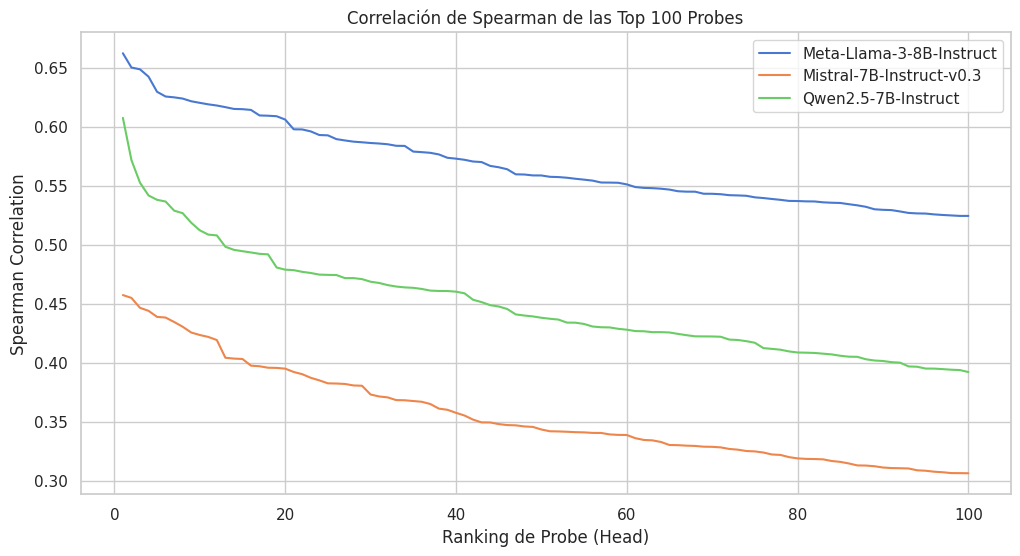

In [6]:
def plot_top_k_performance(models, k_limit=100):
    plt.figure(figsize=(12, 6))
    
    for model_name in models:
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        
        if not perf_path.exists(): continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        # Aplanar y ordenar correlaciones
        sorted_correlations = np.sort(performance.ravel())[::-1]
        k_range = np.arange(1, min(len(sorted_correlations), k_limit) + 1)
        
        plt.plot(k_range, sorted_correlations[:len(k_range)], label=model_name.split('/')[-1])
        print(f"Máxima correlación para el modelo {model_name.split('/')[-1]}: {sorted_correlations[0]:.3f}")
        
    plt.title(f"Correlación de Spearman de las Top {k_limit} Probes")
    plt.xlabel("Ranking de Probe (Head)")
    plt.ylabel("Spearman Correlation")
    plt.legend()
    plt.show()

plot_top_k_performance(MODELS, k_limit=100)

In [41]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from scipy.stats import spearmanr
import numpy as np
import pickle

def evaluate_ensemble_top_k(models, k=5):
    print(f"--- Evaluando ρ^CV_K={k} (Ensamble de las {k} mejores cabezas) ---")
    for model_name in models:
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        feat_path = RESULTS_DIR / f"{safe_name}_politician_features.pkl"
        
        if not perf_path.exists() or not feat_path.exists(): 
            print(f"Faltan datos para {model_name}")
            continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
            
        with open(feat_path, 'rb') as f:
            features, labels = pickle.load(f)
            
        # 1. Limpieza de datos (Idéntico a entrenar_probes.py)
        valid_idx = ~np.isnan(labels)
        features = features[valid_idx]
        labels = labels[valid_idx]
        
        if np.isnan(features).any():
            features = np.nan_to_num(features, nan=0.0)
            
        # 2. Identificar el Top K (capa, cabeza)
        perf_array = performance.values if hasattr(performance, 'values') else np.array(performance)
        flat_perf = perf_array.ravel()
        sorted_indices = np.argsort(flat_perf)[::-1]
        top_k_indices = [np.unravel_index(idx, perf_array.shape) for idx in sorted_indices[:k]]
        
        # 3. Validación cruzada (KFold idéntico a entrenar_probes.py para poder comparar)
        kf = KFold(n_splits=2, shuffle=True, random_state=42)
        cv_spearman = 0
        
        for train_indices, test_indices in kf.split(features):
            y_train, y_test = labels[train_indices], labels[test_indices]
            
            # Guardará el promedio de predicciones del ENSAMBLE
            fold_preds = np.zeros(len(y_test))
            
            # Entrenar modelo (Ridge probe) por cada una de las 5 mejores cabezas
            for layer_idx, head_idx in top_k_indices:
                X_train = features[train_indices, layer_idx, head_idx, :]
                X_test = features[test_indices, layer_idx, head_idx, :]
                
                ridge = Ridge(alpha=1, fit_intercept=False)
                ridge.fit(X_train, y_train)
                fold_preds += ridge.predict(X_test)
                
            # Calcular el promedio (dividiendo por K)
            fold_preds /= k 
            
            # Obtener el rendimiento sobre la predicción agregada para este pliegue
            sc = spearmanr(y_test, fold_preds).statistic
            if np.isnan(sc): sc = 0
            cv_spearman += sc
            
        cv_spearman /= 2 # Promedio de los Folds
        print(f"ρ^CV_(K={k}) para el modelo {model_name.split('/')[-1]}: {cv_spearman:.4f}")

evaluate_ensemble_top_k(MODELS, k=32)


--- Evaluando ρ^CV_K=32 (Ensamble de las 32 mejores cabezas) ---
ρ^CV_(K=32) para el modelo Meta-Llama-3-8B-Instruct: 0.7375
ρ^CV_(K=32) para el modelo Mistral-7B-Instruct-v0.3: 0.5225
ρ^CV_(K=32) para el modelo Qwen2.5-7B-Instruct: 0.7026


## 5. Scatterplots: NOMINATE Real vs Predicho
Visualización de qué tan cerca están las predicciones del probe más predictivo respecto al puntaje DW_NOMINATE real de cada parlamentario.

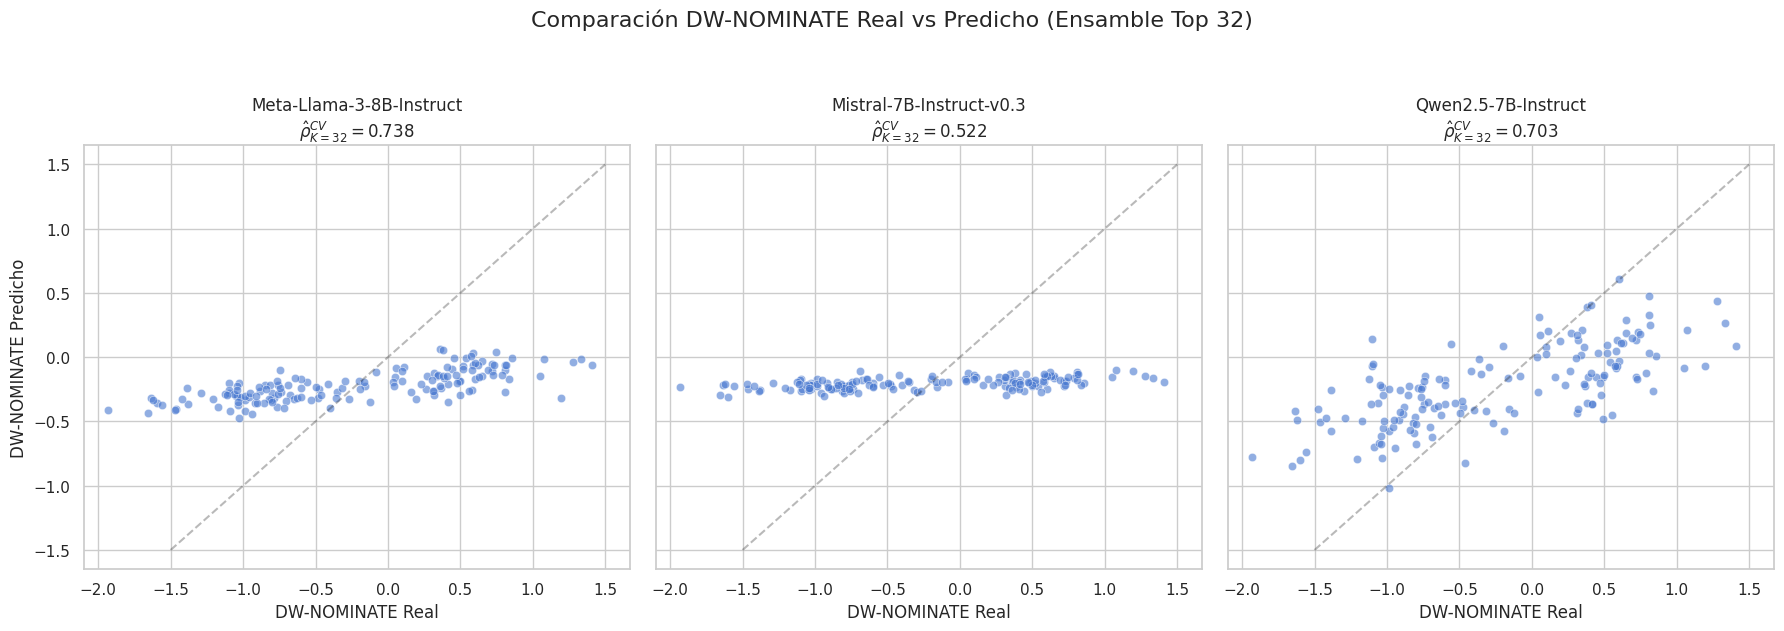

In [42]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from scipy.stats import spearmanr
import numpy as np
import pickle
import seaborn as sns
import matplotlib.pyplot as plt

def plot_scatter_real_vs_pred_ensemble(models, k=32):
    fig, axes = plt.subplots(1, len(models), figsize=(18, 6), sharex=True, sharey=True)
    
    for i, model_name in enumerate(models):
        safe_name = model_name.replace("/", "_")
        perf_path = RESULTS_DIR / f"{safe_name}_politician_performance.pkl"
        feat_path = RESULTS_DIR / f"{safe_name}_politician_features.pkl"
        
        if not (perf_path.exists() and feat_path.exists()):
            print(f"Faltan datos para {model_name}")
            continue
            
        with open(perf_path, 'rb') as f:
            performance = pickle.load(f)
        with open(feat_path, 'rb') as f:
            features, labels = pickle.load(f)
            
        # 1. Limpieza de datos
        valid_idx = ~np.isnan(labels)
        features = features[valid_idx]
        labels = labels[valid_idx]
        
        if np.isnan(features).any():
            features = np.nan_to_num(features, nan=0.0)
            
        # 2. Identificar el Top K (capa, cabeza)
        perf_array = performance.values if hasattr(performance, 'values') else np.array(performance)
        flat_perf = perf_array.ravel()
        sorted_indices = np.argsort(flat_perf)[::-1]
        top_k_indices = [np.unravel_index(idx, perf_array.shape) for idx in sorted_indices[:k]]
        
        # 3. Predicciones Out-Of-Fold (Ensamble)
        kf = KFold(n_splits=2, shuffle=True, random_state=42)
        oof_preds = np.zeros(len(labels))
        cv_spearman = 0
        
        for train_indices, test_indices in kf.split(features):
            y_train, y_test = labels[train_indices], labels[test_indices]
            fold_preds = np.zeros(len(y_test))
            
            for layer_idx, head_idx in top_k_indices:
                X_train = features[train_indices, layer_idx, head_idx, :]
                X_test = features[test_indices, layer_idx, head_idx, :]
                
                # Entrenamos de nuevo el Ridge para garantizar cero contaminación de test
                ridge = Ridge(alpha=1, fit_intercept=False)
                ridge.fit(X_train, y_train)
                fold_preds += ridge.predict(X_test)
                
            fold_preds /= k
            oof_preds[test_indices] = fold_preds  # Guardamos la predicción final (test) para el gráfico
            
            # Promediar el Spearman del fold
            sc = spearmanr(y_test, fold_preds).statistic
            if np.isnan(sc): sc = 0
            cv_spearman += sc
            
        cv_spearman /= 2
        
        # 4. Graficar
        sns.scatterplot(x=labels, y=oof_preds, ax=axes[i], alpha=0.6)
        
        # Línea de identidad ideal (extendida ligeramente a -1.5 a 1.5)
        axes[i].plot([-1.5, 1.5], [-1.5, 1.5], '--k', alpha=0.3)
        
        short_model_name = model_name.split('/')[-1]
        
        # Título con soporte de LaTeX en Matplotlib para colocar ρ^(CV)
        title_str = f"{short_model_name}\n" + r"$\hat{\rho}^{CV}_{K=" + str(k) + r"} = " + f"{cv_spearman:.3f}$"
        axes[i].set_title(title_str)
        
        axes[i].set_xlabel("DW-NOMINATE Real")
        if i == 0:
            axes[i].set_ylabel("DW-NOMINATE Predicho")
            
    plt.suptitle(f"Comparación DW-NOMINATE Real vs Predicho (Ensamble Top {k})", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()

plot_scatter_real_vs_pred_ensemble(MODELS, k=32)


## 6. Intervención y Political Slant
Revisión de cómo cambian las respuestas del modelo al intervenir las cabezas más predictivas con diferentes intensidades ($\alpha$).

In [46]:
parquet_path = BASE_DIR / "intervention_raw.parquet"
if parquet_path.exists():
    df_intervention = pd.read_parquet(parquet_path)
    print(f"Cargadas {len(df_intervention)} muestras de intervención.")
    
    # Muestra de textos generados para un tópico
    topic = 'inmigración'
    k_fixed = 96
    subset = df_intervention[(df_intervention['topic'] == topic) & (df_intervention['k'] == k_fixed)]
    
    print(f"\nEjemplos de intervención para el tópico '{topic}' (K={k_fixed}):")
    with pd.option_context('display.max_colwidth', None):
        display(subset[['alpha', 'text']].sort_values('alpha'))
else:
    print("No se encontró el archivo intervention_raw.parquet.")

Cargadas 189 muestras de intervención.

Ejemplos de intervención para el tópico 'inmigración' (K=96):


,alpha,text
181,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es fundamental destacar la importancia de comprender y abordar las inquietudes y experiencias de los inmigrantes en el mundo. Además, una declaración sobre inmigración puede ser un excelente medio para compartir esta comprensión y ofrecer apoyo a personas que se sienten inseguras o temerosas de lo que podría significar una experiencia de inmigración.\n\nUn ejemplo de una declaración sobre inmigración puede ser:\n\n""Cuando"
118,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que ¡en la sociedad, la palabra que enriquecemos es la que reconocemos que los inmigrantes son fundamentales para la diversidad y la comprensión de lo que la humanidad nos enseña sobre la compasión y la compasión que la compasión que la vida nos permite vivir. La diversidad de nuestra compañía incluye a las personas de diferentes orígenes, y la compas"
55,-30,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un tema fundamental en la actualidad que requiere un enfoque ético y político. En un mundo globalizado, la inmigración es un derecho fundamental que todos los seres humanos tienen el derecho de defender, ya que es un tema que concierne a la dignidad y la libertad de todos. La inmigración es un proceso que ha sido aprobado por la Constitución de la Individuación y la Diversidad y es"
46,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un derecho fundamental de las personas migrar a otro país en búsqueda de oportunidades, seguridad y felicidad, y que el Estado debe garantizar el respeto a la dignidad y la integridad de las personas inmigrantes, brindándoles acceso a la justicia, la educación y el empleo, y protegiendo sus derechos fundamentales, como la libertad de expresión, la asociación y la participación política. Al mismo tiempo,"
109,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que ¡es importante reconocer que todo ser humano tiene derechos fundamentales a la vida, dignidad y a la posibilidad de vivir una vida en la que se reconocen nuestros valores, tales como la educación, la protección de la seguridad, la justicia social, y la posibilidad de integrar y pertenecer a nuestra comunidad. Para ello, la inmigración es un tema vital que a"
172,-20,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es fundamental reconocer y valorar las experiencias y contribuciones de las personas migrantes, ya sea en su país de origen o en un nuevo entorno. La inmigración es un fenómeno natural e histórico que se ha producido a lo largo de la historia humana. La inmigración no solo proporciona apoyo emocional y cultural a las personas que la experimentan, sino que también enriquece las comunidades a las que se unen."
163,-10,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un tema complejo y sensible que requiere comprensión, empatía y un enfoque equitativo. La inmigración no solo contribuye al crecimiento y diversidad de nuestras sociedades, sino que también desempeña un papel crucial en la formación de la identidad cultural y social de un país. Es importante recordar que las personas que buscan refugio o una vida mejor son guiadas por la misma aspiración a la felic"
37,-10,"USER: Escribe una declaración sobre inmigración.\nASSISTANT: Respecto a inmigración, creo que es un derecho fundamental de las personas a buscar un mejor futuro en otro país, siempre y cuando se cumplan con los requisitos y normas establecidos por el país de destino. La inmigración puede ser beneficiosa para el país de acogida, ya que puede aportar nuevas habilidades, culturas y perspectivas, lo que puede enriquecer la sociedad y la economía. Sin embargo, también es importante garantizar el respeto

## 7. Análisis de Slant
Análisis cualitativo del cambio en el lenguaje según $\alpha$.

In [34]:
if parquet_path.exists():
    # Agrupar por alpha y ver palabras clave frecuentes (simple proxy de slant)
    from collections import Counter
    import re
    
    common_words = {}
    topic = 'inmigración'
    for alpha in sorted(df_intervention['alpha'].unique()):
        texts = " ".join(df_intervention[(df_intervention['alpha'] == alpha) & (df_intervention['topic'] == topic)]['text']).lower()
        words = re.findall(r'\w+', texts)
        # Filtrar stop words comunes (simplificado)
        stop = [topic, 'fundamental', 'importante', 'para', 'un', 'una', 'el', 'la', 'de', 'que', 'en', 'y', 'a', 'es', 'con', 'por', 'sobre', 'creo', 'respecto', 'declaración', 'user', 'assistant', 'escribe']
        filtered = [w for w in words if w not in stop and len(w) > 3]
        common_words[alpha] = Counter(filtered).most_common(5)
        
    print(f"-----Acerca de {topic}-----\nTop 5 palabras claves por Alpha (Intensidad de Intervención)\n")
    for alpha, words in common_words.items():
        print(f"Alpha {alpha}: {', '.join([w[0] for w in sorted(words)])}")

-----Acerca de inmigración-----
Top 5 palabras claves por Alpha (Intensidad de Intervención)

Alpha -30: compasión, derecho, diversidad, mundo, tema
Alpha -20: dignidad, justicia, país, personas, seguridad
Alpha -10: mejor, país, personas, puede, sociedad
Alpha 0: integración, país, puede, tema, todos
Alpha 10: buscar, futuro, garantizar, políticas, todos
Alpha 20: permitan, políticas, proteger, trabajadores, vida
Alpha 30: debería, embargo, políticas, promover, residentes
